# 09 — Análise científica dos resultados

Análise local, somente CPU, dos arquivos já produzidos pelos notebooks 07 e 08. **Não carrega checkpoints, não treina nem executa inferência.** Lê CSVs/JSONs e confere métricas a partir das predições já salvas.

Execute as células em ordem no Jupyter local. Também é possível usar o Colab: a primeira célula monta o Drive, lê a pasta do experimento dos notebooks 07/08 e obtém o código atual em um clone temporário separado. Não depende de git pull ou de src/ atualizada no Drive. Instale o ambiente de análise descrito no README com `requirements-analysis.txt`. O ambiente não precisa de PyTorch, torchvision, CUDA ou acesso ao Google Drive. Não use o requirements completo de treinamento para esta tarefa.

As fontes permanecem intactas. Cada execução gera uma pasta nova em `reports/resultados/`, com tabelas CSV/LaTeX, figuras PDF/PNG, relatório Markdown e manifesto de hashes. Médias e desvios são entre as seeds 42/123/456, com **ddof=1**. A comparação é descritiva e não seleciona modelos ou hiperparâmetros pelo teste.

**Colab:** abra a versão atualizada e use “Executar tudo”. O código é obtido em um clone temporário e os resultados são lidos da pasta do experimento no Drive. A avaliação selecionada já está fixada em `20261022T233940Z_c146fc70d66e`; não é necessário criar uma célula extra para definir TEST_DIR.

In [11]:
from pathlib import Path
import sys

PROJECT_ROOT_OVERRIDE = None  # raiz dos resultados: caminho local ou pasta do experimento no Drive
TEST_RUN_ID = '20261022T233940Z_c146fc70d66e'  # avaliação NOVA solicitada; escolha por identidade, não por métricas

def find_project_root(candidates):
    unique = list(dict.fromkeys(Path(p).expanduser().resolve() for p in candidates))
    with_code = [p for p in unique if (p / 'src/analyze_results.py').is_file()]
    with_results = [p for p in with_code if (p / 'results/repetitions_comparison/validation_individual.csv').is_file()]
    if with_results:
        return with_results[0]
    if with_code:
        return with_code[0]  # a auditoria seguinte identificará os arquivos de resultados ausentes
    checked = '\n'.join(str(p / 'src/analyze_results.py') for p in unique)
    raise FileNotFoundError(
        'Não encontrei src/analyze_results.py nos caminhos abaixo:\n' + checked +
        '\nDefina PROJECT_ROOT_OVERRIDE para a raiz correta. '
        'Abrir o notebook pelo GitHub não sincroniza a pasta src/ no Drive. '
        'Se o projeto for um clone, atualize-o com git pull --ff-only nessa pasta; '
        'caso contrário, copie src/ atualizada para ela. Preserve results/. '
        'Depois reexecute esta célula. Não instale analyze_results com pip.'
    )

try:
    from google.colab import drive
except ImportError:
    IN_COLAB = False
else:
    IN_COLAB = True
    drive.mount('/content/drive')

if IN_COLAB:
    import subprocess
    import tempfile
    PROJECT_ROOT = Path(PROJECT_ROOT_OVERRIDE or '/content/drive/MyDrive/plant-disease-classification').expanduser().resolve()
    if not (PROJECT_ROOT / 'results').is_dir():
        raise FileNotFoundError(f'Pasta de resultados ausente: {PROJECT_ROOT / "results"}. Ajuste PROJECT_ROOT_OVERRIDE.')
    CODE_ROOT = Path(tempfile.mkdtemp(prefix='tcc-analise-')) / 'repo'
    cloned = subprocess.run(
        ['git', 'clone', '--depth', '1', 'https://github.com/murilodc/plant-disease-classification.git', str(CODE_ROOT)],
        capture_output=True, text=True,
    )
    if cloned.returncode != 0:
        raise RuntimeError('Falha ao obter código em pasta temporária:\n' + cloned.stdout + cloned.stderr)
    if not (CODE_ROOT / 'src/analyze_results.py').is_file():
        raise FileNotFoundError(f'Script ausente no clone: {CODE_ROOT / "src/analyze_results.py"}')
else:
    if PROJECT_ROOT_OVERRIDE is not None:
        candidates = [PROJECT_ROOT_OVERRIDE]
    else:
        current = Path.cwd()
        candidates = [current, *current.parents, Path.home() / 'Documents/tcc-plant-disease-classification']
    PROJECT_ROOT = find_project_root(candidates)
    CODE_ROOT = PROJECT_ROOT
RESULTS_ROOT = PROJECT_ROOT / 'results'
TEST_DIR = RESULTS_ROOT / 'test_evaluation' / TEST_RUN_ID
if not (TEST_DIR / 'evaluation_manifest.json').is_file():
    raise FileNotFoundError(f'Manifesto da avaliação selecionada ausente: {TEST_DIR / "evaluation_manifest.json"}. Confira PROJECT_ROOT_OVERRIDE e TEST_RUN_ID.')
OUTPUT_DIR = None  # cria pasta nova em PROJECT_ROOT/reports/, fora de results/
sys.path.insert(0, str(CODE_ROOT / 'src'))
sys.modules.pop('analyze_results', None)  # evita reutilizar módulo antigo no mesmo kernel
print('Ambiente:', 'Colab (análise CPU)' if IN_COLAB else 'Jupyter local (análise CPU)')
print('Código:', CODE_ROOT)
print('Projeto com os resultados:', PROJECT_ROOT)
print('Resultados originais:', RESULTS_ROOT)
print('Avaliação fixa desta análise:', TEST_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Ambiente: Colab (análise CPU)
Código: /tmp/tcc-analise-vs02hlco/repo
Projeto com os resultados: /content/drive/MyDrive/plant-disease-classification
Resultados originais: /content/drive/MyDrive/plant-disease-classification/results
Avaliação fixa desta análise: /content/drive/MyDrive/plant-disease-classification/results/test_evaluation/20261022T233940Z_c146fc70d66e


## Inventário e integridade

A auditoria exige 12 execuções por split, os mapas originais de classes e suportes consistentes. Confere os hashes dos artefatos do teste, matrizes contra predições salvas, métricas individuais e consolidadas, ddof=1, tempos e melhores épocas contra os históricos.

Os consolidados de `results/repetitions_comparison/` são a fonte de validação. Resultados individuais antigos de outra GPU não substituem os consolidados. A lista de originais históricos ausentes ou divergentes vai para o relatório. Diferenças de CRLF/LF são registradas sem modificar arquivos.

Se um arquivo necessário estiver ausente ou inconsistente, a execução para com o caminho ou a checagem específica. Este notebook já fixa `TEST_RUN_ID = 20261022T233940Z_c146fc70d66e`, a avaliação nova solicitada. A existência de outras avaliações completas não muda essa escolha. Para outro experimento, altere TEST_RUN_ID explicitamente pela identidade/proveniência, sem consultar qual teve melhores métricas.

In [12]:
import pandas as pd
import numpy as np
import matplotlib
from IPython.display import display, Markdown, Image
from analyze_results import load_saved_results, scientific_tables, metric_display, markdown_table

print('Python:', sys.version.split()[0], '| pandas:', pd.__version__, '| NumPy:', np.__version__, '| matplotlib:', matplotlib.__version__)
data = load_saved_results(RESULTS_ROOT, TEST_DIR)
tables = scientific_tables(data)
print('Avaliação selecionada:', data.test_dir)
print('Artefatos de teste verificados:', len(data.manifest['artifacts_sha256']))
display(data.inventory)
display(data.historical_sources.groupby('status').size().rename('Arquivos').reset_index())
for note in data.notes:
    print(note)

Python: 3.13.16 | pandas: 2.2.3 | NumPy: 2.1.3 | matplotlib: 3.10.0
Avaliação selecionada: /content/drive/MyDrive/plant-disease-classification/results/test_evaluation/20261022T233940Z_c146fc70d66e
Artefatos de teste verificados: 91


,path,bytes,used_in_analysis
0,/content/drive/MyDrive/plant-disease-classific...,3024,True
1,/content/drive/MyDrive/plant-disease-classific...,258,True
2,/content/drive/MyDrive/plant-disease-classific...,3171,True
3,/content/drive/MyDrive/plant-disease-classific...,1689,True
4,/content/drive/MyDrive/plant-disease-classific...,261,True
...,...,...,...
188,/content/drive/MyDrive/plant-disease-classific...,23290,True
189,/content/drive/MyDrive/plant-disease-classific...,44319,True
190,/content/drive/MyDrive/plant-disease-classific...,1303279,True
191,/content/drive/MyDrive/plant-disease-classific...,2121,True


,status,Arquivos
0,hash_idêntico,105


Checkpoints legados não registram seed/modelo/hash do CSV internamente; a identidade depende dos metadados e manifestos associados.
O vínculo histórico da seed 42 ao CSV depende da preservação do original; os hashes das repetições são conferidos.
Aviso salvo na comparação de validação: Nenhum aviso de comparabilidade.
O teste local é semanticamente idêntico ao test_split salvo. A normalização CRLF→LF é registrada separadamente do hash bruto.
A análise usa os consolidados de validação do notebook 07; não substitui seus valores por artefatos individuais locais divergentes.


## Validação: média ± desvio padrão amostral

Valores em porcentagem. O desvio usa a mesma escala percentual, em pontos percentuais. Cada linha reúne três execuções. As métricas macro atribuem peso igual a cada classe; as ponderadas usam o suporte de imagens.

In [13]:
display(metric_display(tables['validation_summary']))
display(tables['validation_individual'][['model_name', 'seed', 'accuracy', 'f1_macro', 'f1_weighted']])

,Modelo,Acurácia (%),Precisão macro (%),Recall macro (%),F1 macro (%),Precisão pond. (%),Recall pond. (%),F1 pond. (%)
0,CNN baseline,"96,019 ± 0,195","95,424 ± 0,186","95,084 ± 0,693","95,124 ± 0,358","96,131 ± 0,219","96,019 ± 0,195","96,000 ± 0,204"
1,ResNet50,"99,425 ± 0,076","99,162 ± 0,082","99,208 ± 0,140","99,178 ± 0,064","99,431 ± 0,079","99,425 ± 0,076","99,424 ± 0,077"
2,DenseNet201,"99,441 ± 0,118","99,216 ± 0,116","99,322 ± 0,099","99,264 ± 0,093","99,448 ± 0,116","99,441 ± 0,118","99,442 ± 0,117"
3,EfficientNet-B0,"99,543 ± 0,095","99,215 ± 0,138","99,365 ± 0,116","99,280 ± 0,130","99,553 ± 0,085","99,543 ± 0,095","99,544 ± 0,094"


,model_name,seed,accuracy,f1_macro,f1_weighted
0,CNN baseline,42,0.961821,0.955367,0.961810
1,ResNet50,42,0.994860,0.992097,0.994845
2,DenseNet201,42,0.994616,0.992959,0.994621
3,EfficientNet-B0,42,0.996207,0.993820,0.996212
4,CNN baseline,123,0.958027,0.949471,0.957788
5,ResNet50,123,0.994493,0.992197,0.994510
6,DenseNet201,123,0.993147,0.991594,0.993159
7,EfficientNet-B0,123,0.995717,0.993249,0.995713
8,CNN baseline,456,0.960720,0.948897,0.960403
9,ResNet50,456,0.993392,0.991045,0.993379


## Teste final: média ± desvio padrão amostral

8.125 imagens por execução. Os desvios quantificam a variação entre treinamentos, sem representar intervalos de confiança sobre novas imagens. Não há teste inferencial ou escolha de modelo nesta análise.

In [14]:
display(metric_display(tables['test_summary']))
display(tables['test_individual'][['model_name', 'seed', 'accuracy', 'f1_macro', 'f1_weighted']])
display(tables['validation_test_differences'][['model_name', 'seed', 'accuracy_delta_pp', 'f1_macro_delta_pp']])

,Modelo,Acurácia (%),Precisão macro (%),Recall macro (%),F1 macro (%),Precisão pond. (%),Recall pond. (%),F1 pond. (%)
0,CNN baseline,"95,938 ± 0,130","95,253 ± 0,132","95,236 ± 0,423","95,146 ± 0,254","96,070 ± 0,147","95,938 ± 0,130","95,928 ± 0,135"
1,ResNet50,"99,458 ± 0,093","99,312 ± 0,223","99,259 ± 0,109","99,278 ± 0,136","99,466 ± 0,091","99,458 ± 0,093","99,458 ± 0,091"
2,DenseNet201,"99,475 ± 0,040","99,216 ± 0,129","99,238 ± 0,097","99,220 ± 0,113","99,480 ± 0,041","99,475 ± 0,040","99,474 ± 0,040"
3,EfficientNet-B0,"99,643 ± 0,033","99,491 ± 0,192","99,505 ± 0,021","99,490 ± 0,094","99,651 ± 0,024","99,643 ± 0,033","99,643 ± 0,031"


,model_name,seed,accuracy,f1_macro,f1_weighted
0,CNN baseline,42,0.960369,0.953740,0.960345
1,CNN baseline,123,0.959877,0.951932,0.959739
2,CNN baseline,456,0.957908,0.948718,0.957762
3,ResNet50,42,0.994708,0.992173,0.994691
4,ResNet50,123,0.993600,0.991820,0.993612
5,ResNet50,456,0.995446,0.994333,0.995429
6,DenseNet201,42,0.994585,0.993405,0.994568
7,DenseNet201,123,0.994462,0.991172,0.994457
8,DenseNet201,456,0.995200,0.992011,0.995199
9,EfficientNet-B0,42,0.996677,0.995543,0.996667


,model_name,seed,accuracy_delta_pp,f1_macro_delta_pp
0,CNN baseline,42,-0.145162,-0.162690
1,ResNet50,42,-0.015281,0.007539
2,DenseNet201,42,-0.003115,0.044569
3,EfficientNet-B0,42,0.047036,0.172339
4,CNN baseline,123,0.184951,0.246047
5,ResNet50,123,-0.089339,-0.037656
6,DenseNet201,123,0.131421,-0.042214
7,EfficientNet-B0,123,0.083676,0.208326
8,CNN baseline,456,-0.281184,-0.017864
9,ResNet50,456,0.205408,0.328747


## Classes e confusões

Compare precisão, recall, F1 e suporte. As cinco classes com menores F1 são uma descrição posterior dos resultados, sem ajustes de treinamento. Contagens e taxas de confusão não são intercambiáveis: a taxa tem como denominador o suporte da classe real.

As matrizes normalizadas são promediadas entre sementes, sem tratar as passagens pelas mesmas imagens como amostras independentes. A validação consolidada não contém matrizes numéricas nem predições por imagem; não se extraem contagens de PNGs.

In [15]:
display(tables['test_difficult_classes'][['model_name', 'class_index', 'class_name', 'support', 'precision_mean', 'recall_mean', 'f1_score_mean', 'f1_score_std']])
display(tables['test_confusions_top_count'])
display(tables['test_confusions_top_rate'])
display(tables['test_error_stability'])
display(tables['class_support'])

,model_name,class_index,class_name,support,precision_mean,recall_mean,f1_score_mean,f1_score_std
7,CNN baseline,7,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,77,0.865947,0.896104,0.879130,0.016051
29,CNN baseline,29,Tomato___Early_blight,149,0.978559,0.800895,0.880668,0.009396
31,CNN baseline,31,Tomato___Leaf_Mold,144,0.849797,0.942130,0.892534,0.033913
30,CNN baseline,30,Tomato___Late_blight,286,0.899206,0.914918,0.906282,0.010006
22,CNN baseline,22,Potato___healthy,24,0.886742,0.944444,0.913364,0.019751
83,DenseNet201,7,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,77,0.943545,0.939394,0.941429,0.013079
85,DenseNet201,9,Corn_(maize)___Northern_Leaf_Blight,148,0.966426,0.970721,0.968551,0.008389
110,DenseNet201,34,Tomato___Target_Spot,210,0.990202,0.963492,0.976608,0.011092
99,DenseNet201,23,Raspberry___healthy,55,1.000000,0.957576,0.977954,0.024005
98,DenseNet201,22,Potato___healthy,24,0.961026,1.000000,0.979864,0.020001


,model_key,model_name,true_index,predicted_index,true_class,predicted_class,errors_mean,errors_std,rate_mean,rate_std,seeds_with_error,source_support
141,baseline_cnn,CNN baseline,32,31,Tomato___Septoria_leaf_spot,Tomato___Leaf_Mold,20.666667,12.858201,0.077987,0.048522,3,265
162,baseline_cnn,CNN baseline,35,28,Tomato___Tomato_Yellow_Leaf_Curl_Virus,Tomato___Bacterial_spot,15.000000,16.522712,0.018680,0.020576,3,803
161,baseline_cnn,CNN baseline,35,15,Tomato___Tomato_Yellow_Leaf_Curl_Virus,Orange___Haunglongbing_(Citrus_greening),13.000000,19.052559,0.016189,0.023727,3,803
88,baseline_cnn,CNN baseline,21,30,Potato___Late_blight,Tomato___Late_blight,11.666667,2.516611,0.078829,0.017004,3,148
114,baseline_cnn,CNN baseline,29,30,Tomato___Early_blight,Tomato___Late_blight,10.666667,4.163332,0.071588,0.027942,3,149
215,densenet201,DenseNet201,7,9,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,Corn_(maize)___Northern_Leaf_Blight,4.666667,1.154701,0.060606,0.014996,3,77
217,densenet201,DenseNet201,9,7,Corn_(maize)___Northern_Leaf_Blight,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,4.333333,1.154701,0.029279,0.007802,3,148
249,densenet201,DenseNet201,34,32,Tomato___Target_Spot,Tomato___Septoria_leaf_spot,3.333333,1.527525,0.015873,0.007274,3,210
234,densenet201,DenseNet201,21,30,Potato___Late_blight,Tomato___Late_blight,3.000000,1.732051,0.020270,0.011703,3,148
250,densenet201,DenseNet201,34,33,Tomato___Target_Spot,Tomato___Spider_mites Two-spotted_spider_mite,3.000000,2.645751,0.014286,0.012599,2,210


,model_key,model_name,true_index,predicted_index,true_class,predicted_class,errors_mean,errors_std,rate_mean,rate_std,seeds_with_error,source_support
34,baseline_cnn,CNN baseline,7,9,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,Corn_(maize)___Northern_Leaf_Blight,7.666667,4.041452,0.099567,0.052486,3,77
88,baseline_cnn,CNN baseline,21,30,Potato___Late_blight,Tomato___Late_blight,11.666667,2.516611,0.078829,0.017004,3,148
141,baseline_cnn,CNN baseline,32,31,Tomato___Septoria_leaf_spot,Tomato___Leaf_Mold,20.666667,12.858201,0.077987,0.048522,3,265
114,baseline_cnn,CNN baseline,29,30,Tomato___Early_blight,Tomato___Late_blight,10.666667,4.163332,0.071588,0.027942,3,149
36,baseline_cnn,CNN baseline,9,7,Corn_(maize)___Northern_Leaf_Blight,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,9.333333,6.110101,0.063063,0.041284,3,148
215,densenet201,DenseNet201,7,9,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,Corn_(maize)___Northern_Leaf_Blight,4.666667,1.154701,0.060606,0.014996,3,77
235,densenet201,DenseNet201,23,6,Raspberry___healthy,Cherry_(including_sour)___healthy,2.333333,2.516611,0.042424,0.045757,2,55
217,densenet201,DenseNet201,9,7,Corn_(maize)___Northern_Leaf_Blight,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,4.333333,1.154701,0.029279,0.007802,3,148
234,densenet201,DenseNet201,21,30,Potato___Late_blight,Tomato___Late_blight,3.000000,1.732051,0.020270,0.011703,3,148
249,densenet201,DenseNet201,34,32,Tomato___Target_Spot,Tomato___Septoria_leaf_spot,3.333333,1.527525,0.015873,0.007274,3,210


,model_key,model_name,errors_seed_42,errors_seed_123,errors_seed_456,errors_mean,errors_std,images_wrong_all_seeds,images_wrong_any_seed
0,baseline_cnn,CNN baseline,322,326,342,330.000000,10.583005,137,576
1,resnet50,ResNet50,43,52,37,44.000000,7.549834,12,89
2,densenet201,DenseNet201,44,45,39,42.666667,3.214550,7,95
3,efficientnet_b0,EfficientNet-B0,27,28,32,29.000000,2.645751,4,66


,class_name,test_images,test_leaves,class_index,test_share_percent,one_error_recall_pp
0,Apple___Apple_scab,95,19,0,1.169231,1.052632
1,Apple___Black_rot,90,14,1,1.107692,1.111111
2,Apple___Cedar_apple_rust,40,10,2,0.492308,2.500000
3,Apple___healthy,247,46,3,3.040000,0.404858
4,Blueberry___healthy,224,30,4,2.756923,0.446429
5,Cherry_(including_sour)___Powdery_mildew,158,13,5,1.944615,0.632911
6,Cherry_(including_sour)___healthy,126,18,6,1.550769,0.793651
7,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,77,77,7,0.947692,1.298701
8,Corn_(maize)___Common_rust_,179,179,8,2.203077,0.558659
9,Corn_(maize)___Northern_Leaf_Blight,148,148,9,1.821538,0.675676


## Custo computacional

Tempos são os registrados nos experimentos originais na GPU, analisados no PC sem GPU. O total de treino inclui treino e validação por época e depende do early stopping. A latência por imagem é uma média de throughput end-to-end em batches, não latência de requisição isolada. Inferência de validação e teste permanece separada, inclusive por diferenças de aquecimento.

Não se deduzem FLOPs, memória ou consumo energético a partir da contagem de parâmetros.

In [16]:
display(tables['cost_summary'])
display(tables['cost_individual'][['model_name', 'seed', 'gpu', 'pytorch_version', 'cuda_version', 'batch_size', 'num_workers', 'epochs_executed', 'training_time_minutes', 'average_time_per_epoch_seconds', 'parameters_millions', 'inference_milliseconds_per_image', 'test_latency_ms', 'warmup_batches']])

,model_key,model_name,training_time_minutes_mean,training_time_minutes_std,average_time_per_epoch_seconds_mean,average_time_per_epoch_seconds_std,epochs_executed_mean,epochs_executed_std,inference_milliseconds_per_image_mean,inference_milliseconds_per_image_std,...,throughput_images_per_second_std,test_latency_ms_mean,test_latency_ms_std,test_inference_seconds_mean,test_inference_seconds_std,test_throughput_mean,test_throughput_std,total_parameters,parameters_millions,training_total_three_seeds_minutes
0,baseline_cnn,CNN baseline,48.730882,1.953186,97.461764,3.906373,30.000000,0.000000,1.458685,0.066310,...,31.982504,1.424014,0.006386,11.570110,0.051883,702.249904,3.143244,398182,0.398182,146.192646
1,resnet50,ResNet50,43.635967,6.135291,187.050023,0.488697,14.000000,2.000000,1.494099,0.073967,...,32.526517,1.418493,0.005201,11.525254,0.042261,704.979918,2.580204,23585894,23.585894,130.907900
2,densenet201,DenseNet201,78.659252,31.213810,329.285237,0.450522,14.333333,5.686241,2.455827,0.006790,...,1.127248,2.404209,0.008758,19.534199,0.071159,415.940877,1.517135,18165926,18.165926,235.977757
3,efficientnet_b0,EfficientNet-B0,36.645834,8.628437,115.822050,0.667638,19.000000,4.582576,1.456555,0.094747,...,43.739751,1.433148,0.029669,11.644326,0.241057,697.962274,14.312533,4056226,4.056226,109.937502


,model_name,seed,gpu,pytorch_version,cuda_version,batch_size,num_workers,epochs_executed,training_time_minutes,average_time_per_epoch_seconds,parameters_millions,inference_milliseconds_per_image,test_latency_ms,warmup_batches
0,CNN baseline,42,NVIDIA L4,2.11.0+cu130,13.0,32,2,30,46.575562,93.151124,0.398182,1.382837,1.422089,0
1,ResNet50,42,NVIDIA L4,2.11.0+cu130,13.0,32,2,16,49.729834,186.486878,23.585894,1.434424,1.424420,0
2,DenseNet201,42,NVIDIA L4,2.11.0+cu130,13.0,32,2,16,87.672016,328.770060,18.165926,2.448214,2.394563,0
3,EfficientNet-B0,42,NVIDIA L4,2.11.0+cu130,13.0,32,2,24,46.021404,115.053510,4.056226,1.377795,1.410153,0
4,CNN baseline,123,NVIDIA L4,2.11.0+cu130,13.0,32,2,30,49.233317,98.466633,0.398182,1.505681,1.418811,0
5,ResNet50,123,NVIDIA L4,2.11.0+cu130,13.0,32,2,12,37.460074,187.300372,23.585894,1.471018,1.416366,0
6,DenseNet201,123,NVIDIA L4,2.11.0+cu130,13.0,32,2,8,43.930702,329.480262,18.165926,2.461257,2.406401,0
7,EfficientNet-B0,123,NVIDIA L4,2.11.0+cu130,13.0,32,2,15,29.038471,116.153885,4.056226,1.561697,1.466637,0
8,CNN baseline,456,NVIDIA L4,2.11.0+cu130,13.0,32,2,30,50.383767,100.767534,0.398182,1.487537,1.431140,0
9,ResNet50,456,NVIDIA L4,2.11.0+cu130,13.0,32,2,14,43.717991,187.362820,23.585894,1.576855,1.414692,0


## Exportação para redação acadêmica

Gera tabelas em CSV e LaTeX com booktabs, oito figuras em PDF vetorial e PNG 300 dpi, relatório fundamentado nos valores lidos e manifesto de integridade. O diretório de destino deve ser novo e ficar fora de `results/`. Os hashes das fontes são conferidos novamente ao final.

In [17]:
from analyze_results import run_analysis
OUTPUT_DIR = run_analysis(PROJECT_ROOT, test_dir=data.test_dir, output_dir=OUTPUT_DIR)
print('Saída:', OUTPUT_DIR)
print('Relatório:', OUTPUT_DIR / 'relatorio_resultados.md')
print('Tabelas:', OUTPUT_DIR / 'tables')
print('Figuras:', OUTPUT_DIR / 'figures')

Saída: /content/drive/MyDrive/plant-disease-classification/reports/resultados/20261023T011313Z_77ff57b0
Relatório: /content/drive/MyDrive/plant-disease-classification/reports/resultados/20261023T011313Z_77ff57b0/relatorio_resultados.md
Tabelas: /content/drive/MyDrive/plant-disease-classification/reports/resultados/20261023T011313Z_77ff57b0/tables
Figuras: /content/drive/MyDrive/plant-disease-classification/reports/resultados/20261023T011313Z_77ff57b0/figures


[Abrir relatório Markdown](drive/MyDrive/plant-disease-classification/reports/resultados/20261023T011313Z_77ff57b0/relatorio_resultados.md)

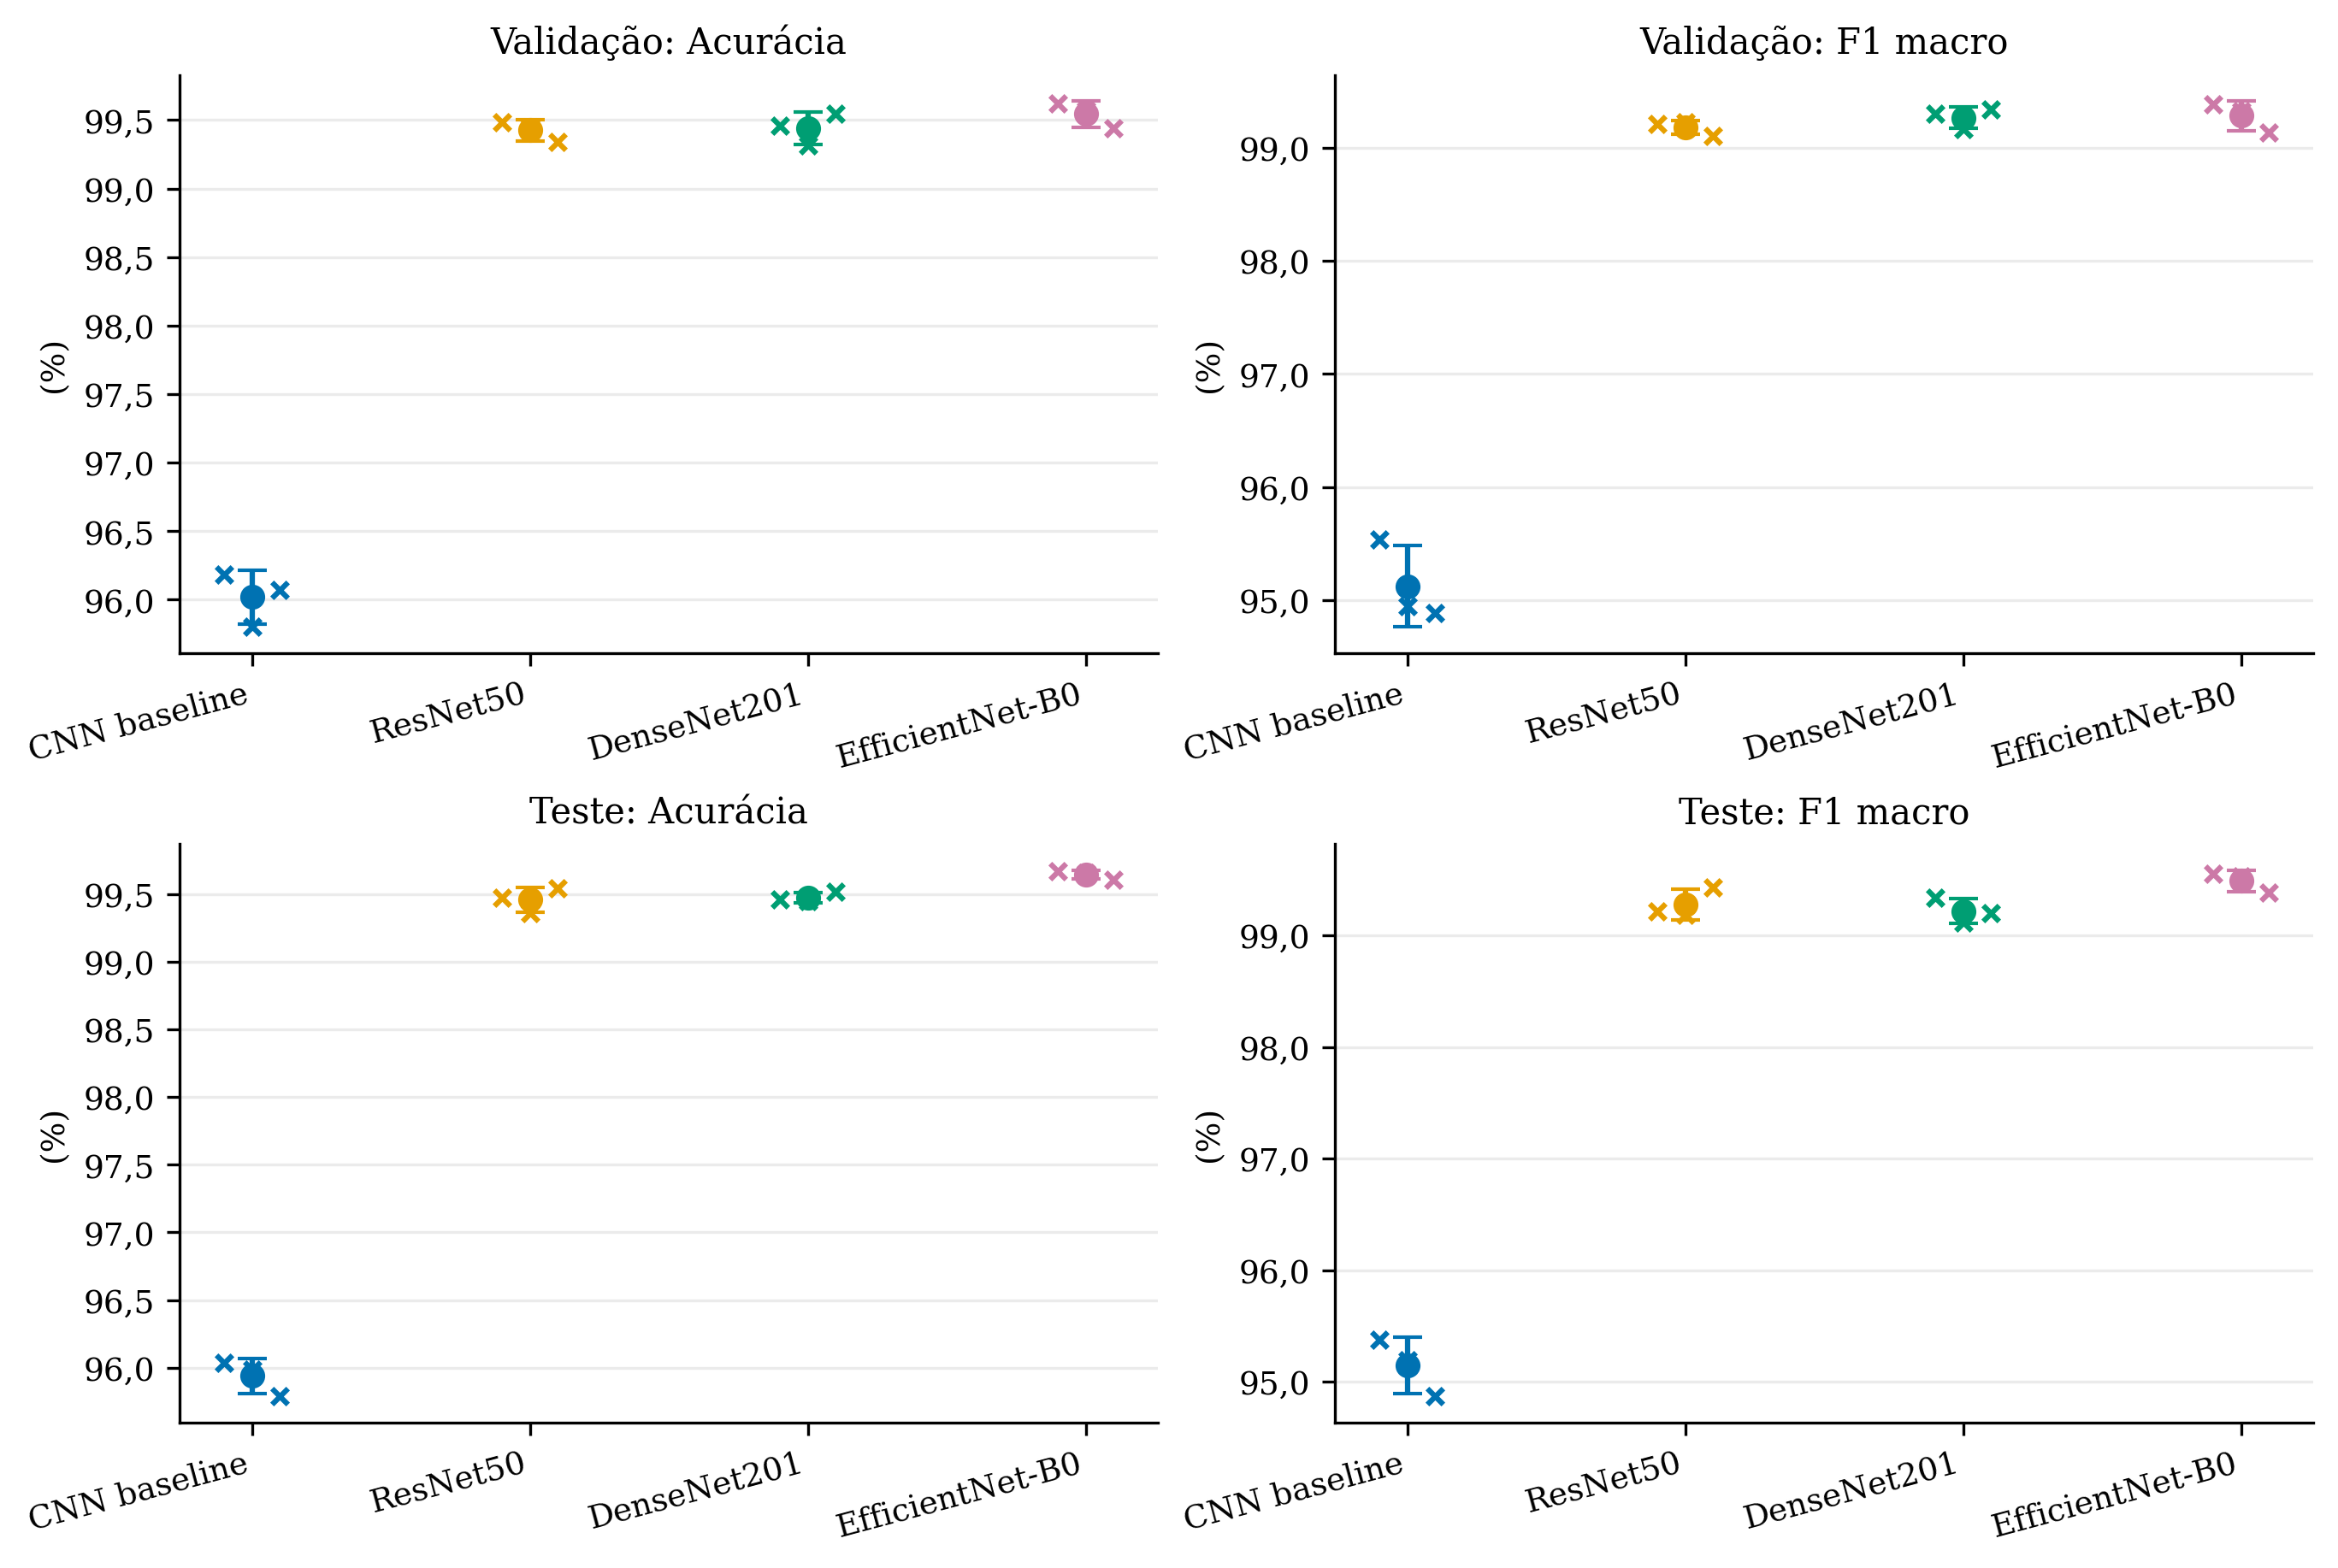

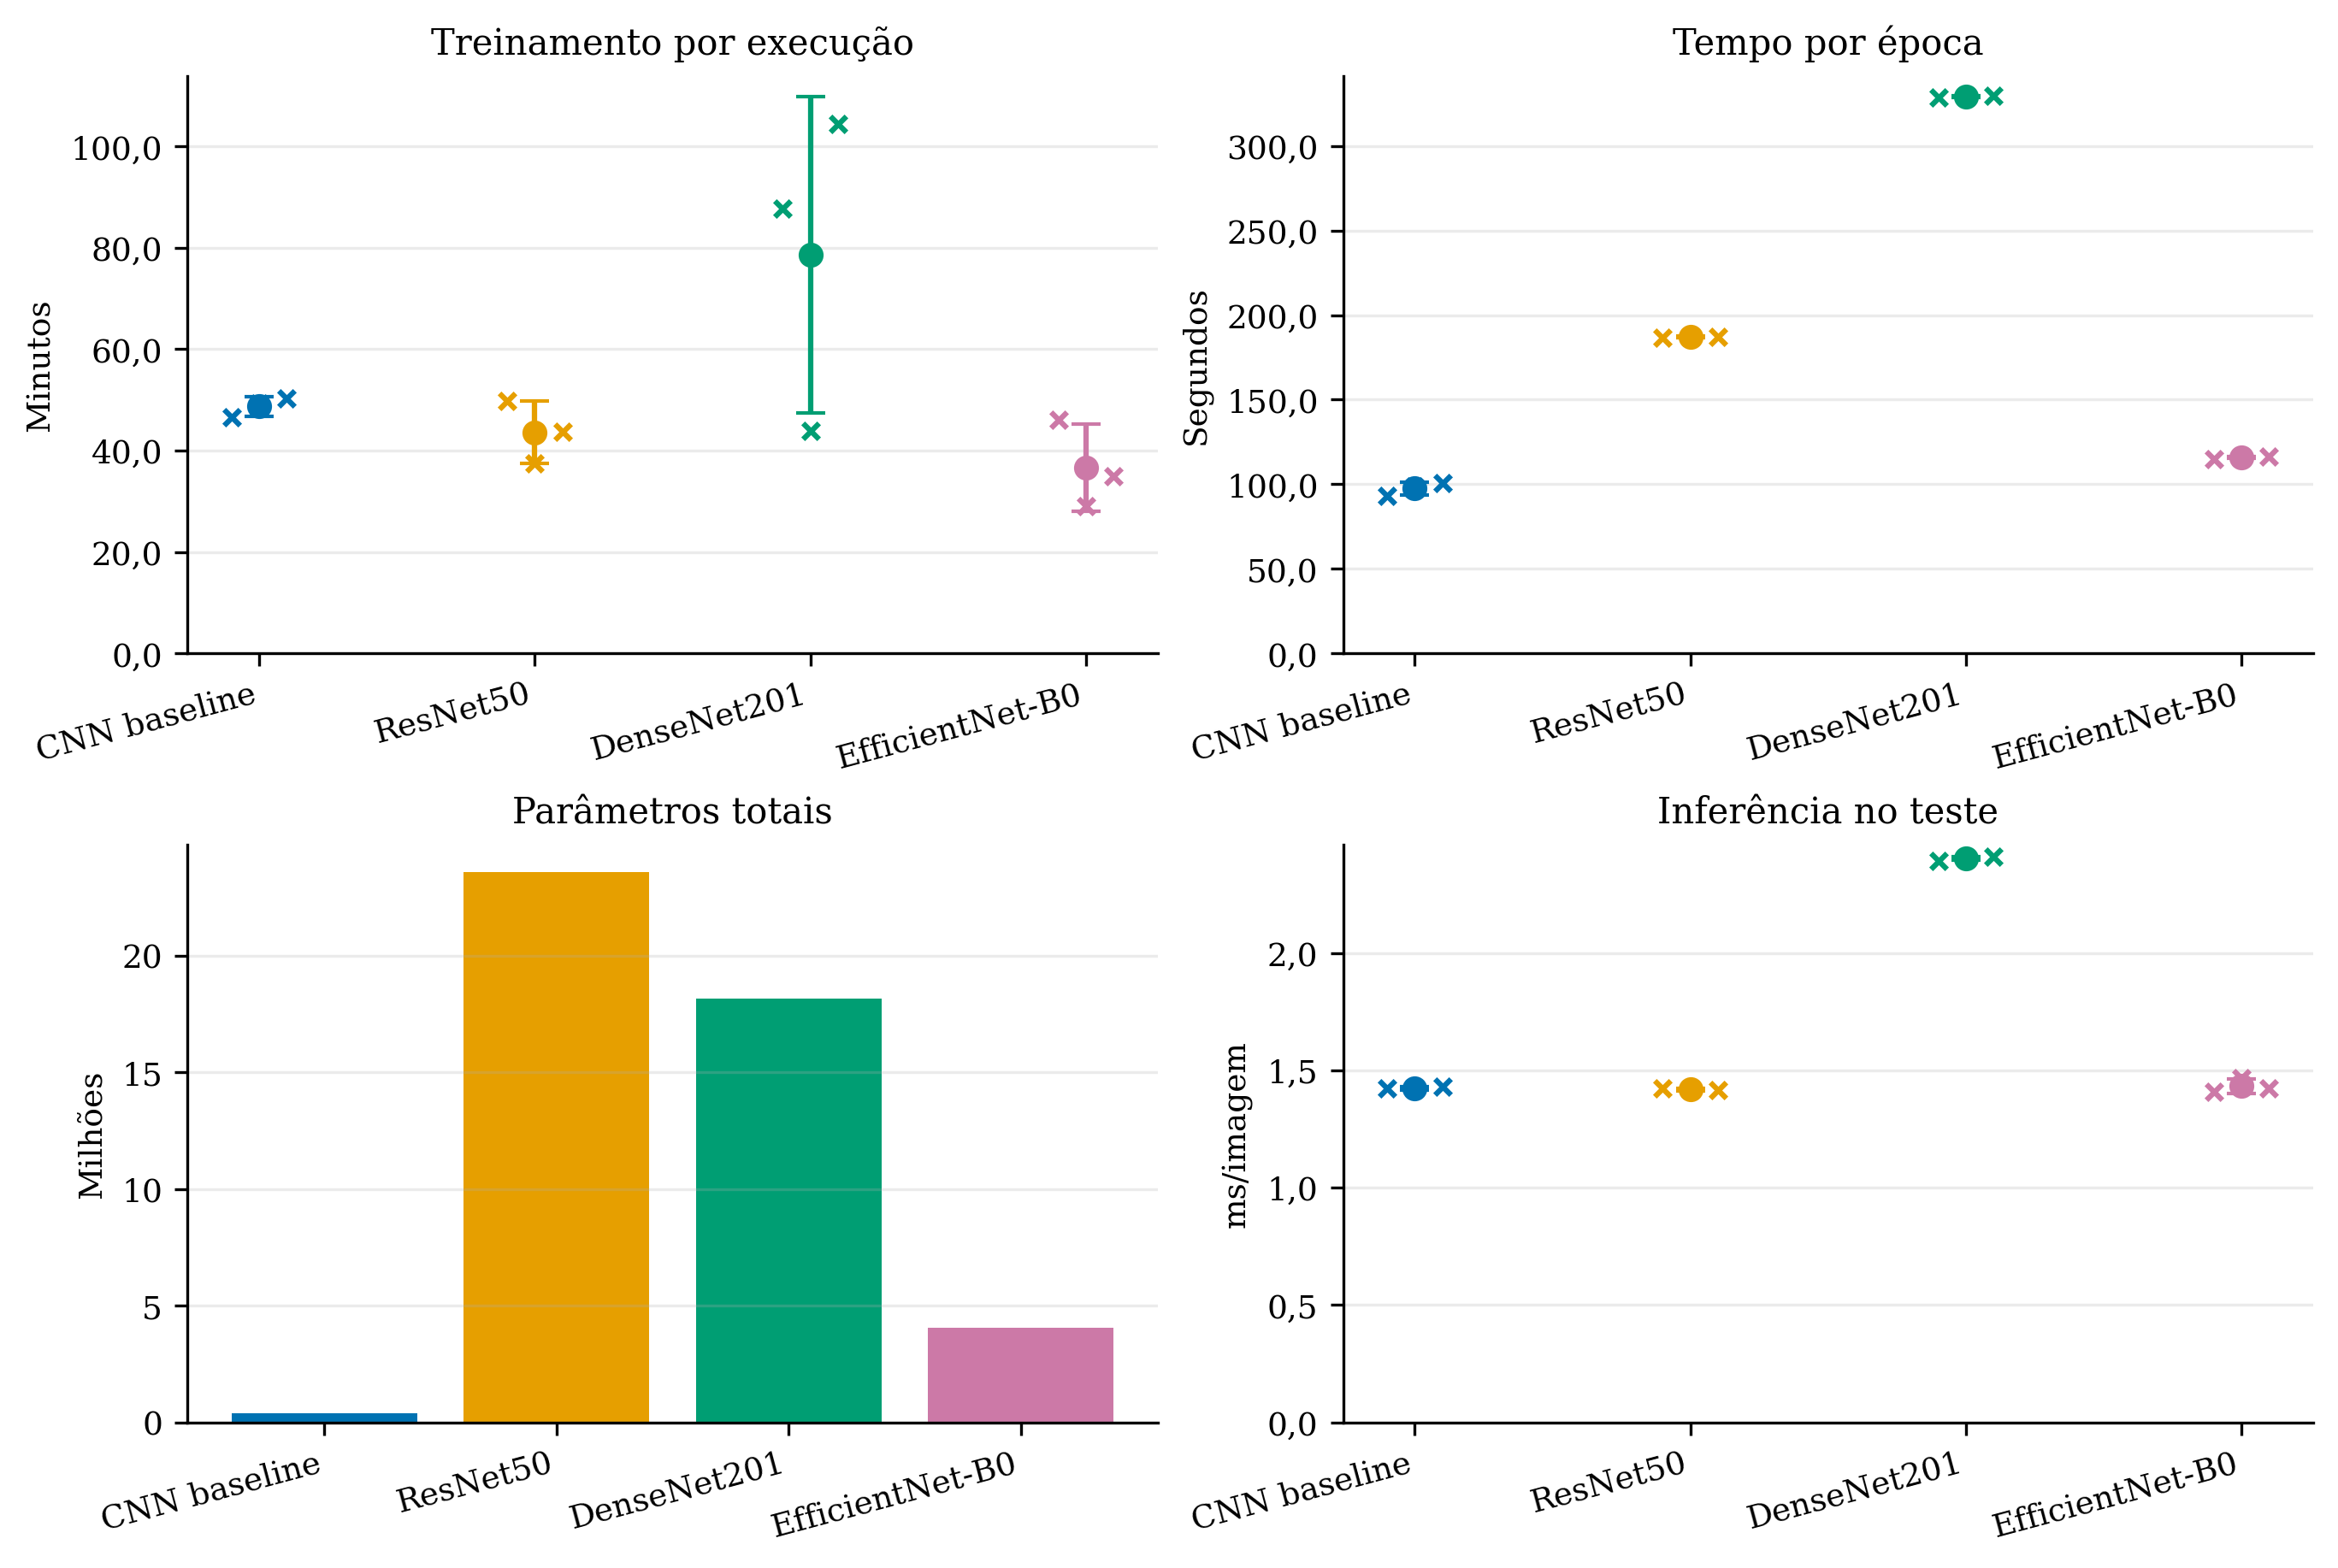

# Resultados e discussão: base empírica para o TCC2

## Escopo e método de análise

Foram analisados exclusivamente CSVs e JSONs de resultados já salvos. Nenhum modelo foi carregado, treinado ou executado. As predições existentes foram usadas para conferir matrizes e métricas, sem nova inferência. São quatro arquiteturas, três sementes (42, 123 e 456), 8.172 imagens de validação e 8.125 de teste, com 38 classes.

As médias são aritméticas entre sementes. O desvio padrão é amostral, com ddof=1 e n=3. Nas tabelas percentuais, os desvios são expressos na mesma escala, em pontos percentuais. Não representam intervalos de confiança nem incerteza sobre uma população de imagens. As mesmas imagens são usadas nas três sementes, portanto não há 24.375 observações de teste independentes.

Os checkpoints foram fixados pela menor loss de validação antes do teste, conforme o manifesto final. A comparação de teste é descritiva: não seleciona arquitetura, hiperparâmetros ou checkpoint. Não foi realizado teste inferencial de superioridade estatística.

## Resultados de validação

| Modelo | Acurácia (%) | Precisão macro (%) | Recall macro (%) | F1 macro (%) | Precisão pond. (%) | Recall pond. (%) | F1 pond. (%) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| CNN baseline | 96,019 ± 0,195 | 95,424 ± 0,186 | 95,084 ± 0,693 | 95,124 ± 0,358 | 96,131 ± 0,219 | 96,019 ± 0,195 | 96,000 ± 0,204 |
| ResNet50 | 99,425 ± 0,076 | 99,162 ± 0,082 | 99,208 ± 0,140 | 99,178 ± 0,064 | 99,431 ± 0,079 | 99,425 ± 0,076 | 99,424 ± 0,077 |
| DenseNet201 | 99,441 ± 0,118 | 99,216 ± 0,116 | 99,322 ± 0,099 | 99,264 ± 0,093 | 99,448 ± 0,116 | 99,441 ± 0,118 | 99,442 ± 0,117 |
| EfficientNet-B0 | 99,543 ± 0,095 | 99,215 ± 0,138 | 99,365 ± 0,116 | 99,280 ± 0,130 | 99,553 ± 0,085 | 99,543 ± 0,095 | 99,544 ± 0,094 |

## Resultados finais de teste

| Modelo | Acurácia (%) | Precisão macro (%) | Recall macro (%) | F1 macro (%) | Precisão pond. (%) | Recall pond. (%) | F1 pond. (%) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| CNN baseline | 95,938 ± 0,130 | 95,253 ± 0,132 | 95,236 ± 0,423 | 95,146 ± 0,254 | 96,070 ± 0,147 | 95,938 ± 0,130 | 95,928 ± 0,135 |
| ResNet50 | 99,458 ± 0,093 | 99,312 ± 0,223 | 99,259 ± 0,109 | 99,278 ± 0,136 | 99,466 ± 0,091 | 99,458 ± 0,093 | 99,458 ± 0,091 |
| DenseNet201 | 99,475 ± 0,040 | 99,216 ± 0,129 | 99,238 ± 0,097 | 99,220 ± 0,113 | 99,480 ± 0,041 | 99,475 ± 0,040 | 99,474 ± 0,040 |
| EfficientNet-B0 | 99,643 ± 0,033 | 99,491 ± 0,192 | 99,505 ± 0,021 | 99,490 ± 0,094 | 99,651 ± 0,024 | 99,643 ± 0,033 | 99,643 ± 0,031 |

### Interpretação dos resultados globais

- **CNN baseline:** acurácia de 95,938 ± 0,130% e F1 macro de 95,146 ± 0,254%. A diferença média teste − validação foi -0,080 p.p. em acurácia e 0,022 p.p. em F1 macro. O F1 ponderado excedeu o macro em 0,782 p.p., indicando que a agregação pelo suporte favorece classes mais frequentes com maior desempenho.
- **ResNet50:** acurácia de 99,458 ± 0,093% e F1 macro de 99,278 ± 0,136%. A diferença média teste − validação foi 0,034 p.p. em acurácia e 0,100 p.p. em F1 macro. O F1 ponderado excedeu o macro em 0,180 p.p., indicando que a agregação pelo suporte favorece classes mais frequentes com maior desempenho.
- **DenseNet201:** acurácia de 99,475 ± 0,040% e F1 macro de 99,220 ± 0,113%. A diferença média teste − validação foi 0,034 p.p. em acurácia e -0,044 p.p. em F1 macro. O F1 ponderado excedeu o macro em 0,255 p.p., indicando que a agregação pelo suporte favorece classes mais frequentes com maior desempenho.
- **EfficientNet-B0:** acurácia de 99,643 ± 0,033% e F1 macro de 99,490 ± 0,094%. A diferença média teste − validação foi 0,100 p.p. em acurácia e 0,210 p.p. em F1 macro. O F1 ponderado excedeu o macro em 0,153 p.p., indicando que a agregação pelo suporte favorece classes mais frequentes com maior desempenho.

A maior média observada de acurácia foi a de EfficientNet-B0, e a maior média observada de F1 macro foi a de EfficientNet-B0. Isso descreve esta divisão fixa e estas três sementes, sem demonstrar superioridade estatística ou justificar nova seleção pelo teste.

DenseNet201 − ResNet50 correspondeu a 0,016 p.p. de acurácia e -0,058 p.p. de F1 macro. A ordenação depende da métrica. A acurácia é influenciada pelo suporte das classes, enquanto o F1 macro dá igual peso a cada classe. O recall ponderado coincide com a acurácia neste problema de classificação multiclasse com um rótulo por imagem, por identidade matemática, não como evidência independente.

As diferenças entre validação e teste não indicam isoladamente sobreajuste: os conjuntos são distintos, com composição e suporte próprios, e a validação foi usada para escolher a época. Nenhum intervalo de confiança ou valor-p é inferido das barras de desvio padrão.

## Dificuldades de classificação e suporte

O suporte de teste varia de 24 imagens (Potato___healthy) a 824 (Orange___Haunglongbing_(Citrus_greening)), razão de 34,33 entre extremos. Há 3834 leaf_id distintos no teste. Imagens da mesma folha podem permanecer correlacionadas dentro do split. A tabela class_support.csv fornece imagens, folhas distintas e a variação de recall causada por um único erro por classe.

### CNN baseline: cinco menores F1 médios de teste

| Classe | n | Precisão (%) | Recall (%) | F1 (%) |
| --- | --- | --- | --- | --- |
| Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot | 77 | 86,59 ± 5,00 | 89,61 ± 4,68 | 87,91 ± 1,61 |
| Tomato___Early_blight | 149 | 97,86 ± 2,03 | 80,09 ± 1,69 | 88,07 ± 0,94 |
| Tomato___Leaf_Mold | 144 | 84,98 ± 6,67 | 94,21 ± 0,80 | 89,25 ± 3,39 |
| Tomato___Late_blight | 286 | 89,92 ± 2,30 | 91,49 ± 4,05 | 90,63 ± 1,00 |
| Potato___healthy | 24 | 88,67 ± 6,04 | 94,44 ± 2,41 | 91,34 ± 1,98 |

Principais confusões direcionais por contagem média:

| Classe real | Classe predita | Erros/execução | Taxa origem (%) | n origem | Seeds com erro |
| --- | --- | --- | --- | --- | --- |
| Tomato___Septoria_leaf_spot | Tomato___Leaf_Mold | 20,67 ± 12,86 | 7,80 ± 4,85 | 265 | 3 |
| Tomato___Tomato_Yellow_Leaf_Curl_Virus | Tomato___Bacterial_spot | 15,00 ± 16,52 | 1,87 ± 2,06 | 803 | 3 |
| Tomato___Tomato_Yellow_Leaf_Curl_Virus | Orange___Haunglongbing_(Citrus_greening) | 13,00 ± 19,05 | 1,62 ± 2,37 | 803 | 3 |
| Potato___Late_blight | Tomato___Late_blight | 11,67 ± 2,52 | 7,88 ± 1,70 | 148 | 3 |
| Tomato___Early_blight | Tomato___Late_blight | 10,67 ± 4,16 | 7,16 ± 2,79 | 149 | 3 |

### ResNet50: cinco menores F1 médios de teste

| Classe | n | Precisão (%) | Recall (%) | F1 (%) |
| --- | --- | --- | --- | --- |
| Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot | 77 | 96,95 ± 3,17 | 93,07 ± 3,27 | 94,92 ± 1,70 |
| Corn_(maize)___Northern_Leaf_Blight | 148 | 96,49 ± 1,58 | 98,42 ± 1,70 | 97,44 ± 0,84 |
| Tomato___Early_blight | 149 | 98,21 ± 1,36 | 97,54 ± 0,77 | 97,87 ± 0,69 |
| Raspberry___healthy | 55 | 98,76 ± 1,07 | 97,58 ± 4,20 | 98,14 ± 2,48 |
| Potato___Late_blight | 148 | 100,00 ± 0,00 | 96,40 ± 0,78 | 98,16 ± 0,40 |

Principais confusões direcionais por contagem média:

| Classe real | Classe predita | Erros/execução | Taxa origem (%) | n origem | Seeds com erro |
| --- | --- | --- | --- | --- | --- |
| Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot | Corn_(maize)___Northern_Leaf_Blight | 5,33 ± 2,52 | 6,93 ± 3,27 | 77 | 3 |
| Pepper,_bell___healthy | Pepper,_bell___Bacterial_spot | 4,33 ± 2,08 | 1,95 ± 0,94 | 222 | 3 |
| Potato___Late_blight | Tomato___Late_blight | 3,67 ± 1,15 | 2,48 ± 0,78 | 148 | 3 |
| Tomato___Early_blight | Tomato___Late_blight | 2,67 ± 0,58 | 1,79 ± 0,39 | 149 | 3 |
| Corn_(maize)___Northern_Leaf_Blight | Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot | 2,33 ± 2,52 | 1,58 ± 1,70 | 148 | 2 |

### DenseNet201: cinco menores F1 médios de teste

| Classe | n | Precisão (%) | Recall (%) | F1 (%) |
| --- | --- | --- | --- | --- |
| Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot | 77 | 94,35 ± 1,47 | 93,94 ± 1,50 | 94,14 ± 1,31 |
| Corn_(maize)___Northern_Leaf_Blight | 148 | 96,64 ± 1,13 | 97,07 ± 0,78 | 96,86 ± 0,84 |
| Tomato___Target_Spot | 210 | 99,02 ± 0,49 | 96,35 ± 1,92 | 97,66 ± 1,11 |
| Raspberry___healthy | 55 | 100,00 ± 0,00 | 95,76 ± 4,58 | 97,80 ± 2,40 |
| Potato___healthy | 24 | 96,10 ± 3,85 | 100,00 ± 0,00 | 97,99 ± 2,00 |

Principais confusões direcionais por contagem média:

| Classe real | Classe predita | Erros/execução | Taxa origem (%) | n origem | Seeds com erro |
| --- | --- | --- | --- | --- | --- |
| Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot | Corn_(maize)___Northern_Leaf_Blight | 4,67 ± 1,15 | 6,06 ± 1,50 | 77 | 3 |
| Corn_(maize)___Northern_Leaf_Blight | Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot | 4,33 ± 1,15 | 2,93 ± 0,78 | 148 | 3 |
| Tomato___Target_Spot | Tomato___Septoria_leaf_spot | 3,33 ± 1,53 | 1,59 ± 0,73 | 210 | 3 |
| Potato___Late_blight | Tomato___Late_blight | 3,00 ± 1,73 | 2,03 ± 1,17 | 148 | 3 |
| Tomato___Target_Spot | Tomato___Spider_mites Two-spotted_spider_mite | 3,00 ± 2,65 | 1,43 ± 1,26 | 210 | 2 |

### EfficientNet-B0: cinco menores F1 médios de teste

| Classe | n | Precisão (%) | Recall (%) | F1 (%) |
| --- | --- | --- | --- | --- |
| Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot | 77 | 95,28 ± 6,02 | 96,10 ± 3,44 | 95,53 ± 1,44 |
| Corn_(maize)___Northern_Leaf_Blight | 148 | 97,81 ± 1,90 | 97,30 ± 3,58 | 97,50 ± 0,93 |
| Raspberry___healthy | 55 | 98,28 ± 2,99 | 98,18 ± 1,82 | 98,19 ± 0,87 |
| Tomato___Early_blight | 149 | 99,10 ± 0,38 | 98,21 ± 1,40 | 98,65 ± 0,68 |
| Tomato___Late_blight | 286 | 98,50 ± 0,52 | 98,95 ± 0,61 | 98,72 ± 0,20 |

Principais confusões direcionais por contagem média:

| Classe real | Classe predita | Erros/execução | Taxa origem (%) | n origem | Seeds com erro |
| --- | --- | --- | --- | --- | --- |
| Corn_(maize)___Northern_Leaf_Blight | Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot | 4,00 ± 5,29 | 2,70 ± 3,58 | 148 | 2 |
| Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot | Corn_(maize)___Northern_Leaf_Blight | 3,00 ± 2,65 | 3,90 ± 3,44 | 77 | 2 |
| Tomato___Bacterial_spot | Tomato___Tomato_Yellow_Leaf_Curl_Virus | 2,67 ± 2,52 | 0,84 ± 0,79 | 319 | 2 |
| Tomato___Early_blight | Tomato___Late_blight | 2,67 ± 2,08 | 1,79 ± 1,40 | 149 | 3 |
| Pepper,_bell___Bacterial_spot | Tomato___Septoria_leaf_spot | 1,33 ± 2,31 | 0,91 ± 1,57 | 147 | 1 |

Os pares acima são observações das matrizes, sem inspeção visual das imagens. Semelhança de sintomas, qualidade da imagem ou erros de anotação seriam hipóteses a investigar, não causas demonstradas por estas métricas. Taxas por classe de origem e contagens respondem a perguntas diferentes: uma classe frequente pode contribuir mais erros absolutos sem ter a maior taxa. O arquivo test_confusions_top_rate.csv apresenta a comparação por taxa.

### Persistência dos erros entre sementes

| model_name | errors_seed_42 | errors_seed_123 | errors_seed_456 | images_wrong_all_seeds | images_wrong_any_seed |
| --- | --- | --- | --- | --- | --- |
| CNN baseline | 322 | 326 | 342 | 137 | 576 |
| ResNet50 | 43 | 52 | 37 | 12 | 89 |
| DenseNet201 | 44 | 45 | 39 | 7 | 95 |
| EfficientNet-B0 | 27 | 28 | 32 | 4 | 66 |

Erros em todas as sementes apontam exemplos persistentemente difíceis nas execuções disponíveis. A união e a interseção não são desempenho de ensemble: nenhuma combinação de modelos foi executada ou selecionada.

## Custo computacional observado

| Modelo | Parâmetros (M) | Treino min | Época s | Épocas | Inferência val. ms/img | Inferência teste ms/img |
| --- | --- | --- | --- | --- | --- | --- |
| CNN baseline | 0,398 | 48,73 ± 1,95 | 97,46 ± 3,91 | 30,00 ± 0,00 | 1,459 ± 0,066 | 1,424 ± 0,006 |
| ResNet50 | 23,586 | 43,64 ± 6,14 | 187,05 ± 0,49 | 14,00 ± 2,00 | 1,494 ± 0,074 | 1,418 ± 0,005 |
| DenseNet201 | 18,166 | 78,66 ± 31,21 | 329,29 ± 0,45 | 14,33 ± 5,69 | 2,456 ± 0,007 | 2,404 ± 0,009 |
| EfficientNet-B0 | 4,056 | 36,65 ± 8,63 | 115,82 ± 0,67 | 19,00 ± 4,58 | 1,457 ± 0,095 | 1,433 ± 0,030 |

Condições registradas na validação:

| gpu | gpu_total_memory_gb | selected_device | pytorch_version | cuda_version | batch_size | num_workers | input_size |
| --- | --- | --- | --- | --- | --- | --- | --- |
| NVIDIA L4 | 23.65915136 | cuda | 2.11.0+cu130 | 13.0 | 32 | 2 | 3x224x224 |

Teste: GPU NVIDIA L4, PyTorch 2.11.0+cu130, torchvision 0.26.0+cu130, CUDA 13.0, batch 32, workers 2. Aquecimento de teste registrado: [0] batches.

O tempo acumulado de treinamento das 12 execuções, somando os tempos por época registrados, foi 10,38 horas. Esse valor inclui treino e validação por época, mas não necessariamente inicialização, leitura de checkpoints, gráficos ou demais custos fora do loop. A soma das três seeds por arquitetura está em cost_summary.csv.

O tempo total depende tanto do custo por época quanto do early stopping. O número de épocas não é mantido igual entre arquiteturas, portanto o total não mede somente complexidade da rede. A variabilidade do tempo por época é calculada entre as médias de cada execução, sem tratar cada época como uma repetição independente.

A baseline alcançou 30 épocas em todas as sementes. Isso descreve a duração observada; não demonstra, por si só, convergência, subtreinamento ou necessidade de alterar o protocolo após observar o teste.

EfficientNet-B0 registrou 10,19 vezes os parâmetros da baseline, com tempo médio por época de 115,82 ± 0,67 s frente a 97,46 ± 3,91 s. Contagem de parâmetros não equivale a FLOPs, memória, consumo de energia ou latência: esses fatores não podem ser concluídos sem medições próprias.

Os tempos de inferência são medidas end-to-end com batches, carregamento e transferência de dados, divididas pelo número de imagens. Não são latências de requisições individuais. O teste foi registrado sem aquecimento adicional, e o protocolo de validação usa aquecimento em CUDA no código de origem. Os tempos dos dois splits são apresentados separadamente e não interpretados como aceleração causada pelo split. Executar esta análise no PC apenas processa arquivos: não mede o desempenho dos modelos no hardware local.



In [18]:
import os
relative = Path(os.path.relpath(OUTPUT_DIR, Path.cwd())).as_posix()
display(Markdown(f'[Abrir relatório Markdown]({relative}/relatorio_resultados.md)'))
for figure in ('01_metricas', '06_custo_computacional'):
    display(Image(filename=str(OUTPUT_DIR / 'figures' / (figure + '.png')), width=900))
report = (OUTPUT_DIR / 'relatorio_resultados.md').read_text(encoding='utf-8')
display(Markdown(report.split('## Integridade e arquivos ausentes')[0]))

## Leitura científica e limitações

- Maiores médias observadas não demonstram superioridade estatística. As barras são desvios entre três sementes, não intervalos de confiança.
- Uma divisão fixa e imagens do PlantVillage não estabelecem generalização para campo. Folhas distintas entre splits reduzem uma fonte de vazamento, sem eliminar todas as dependências possíveis.
- A baseline é treinada do zero e as redes de transferência partem de pré-treinamento. A comparação não isola o efeito causal da arquitetura.
- Suportes pequenos tornam métricas por classe sensíveis a poucos erros. Não se atribui a causa das confusões a sintomas ou qualidade visual sem inspeção própria.
- Consulte `historical_sources.csv` para saber quais originais faltam para auditoria completa. Os CSVs consolidados permitem esta análise sem carregar esses checkpoints.
- Qualquer hipótese sugerida pelo teste é uma observação posterior. Não altere retrospectivamente os modelos ou hiperparâmetros deste experimento.

Para o TCC, utilize os PDFs das figuras e as tabelas .tex compactas. O relatório inclui legendas, unidades, fontes locais, limites de interpretação e um exemplo de inclusão de figura no LaTeX.